# Tree Species Classification — Manoj Bhattarai

**Assigned work:** Sections 16–17 — ResNet50 improvement experiment and conclusions

**Time-saving setting:** The improved ResNet50 is trained for **2 epochs** to keep the experiment short. This is a quick comparison, not a fully optimized training run.

**How to run:** Run the notebook from the first cell, in order. Sections 1–12 are shared with the other members. In Section 3, set `data_dir` to the dataset folder containing `train`, `val`, and `test` subfolders. The class subfolders must be consistent across all splits.

The notebook prepares baseline checkpoints if they are missing. Training missing baseline models can still take time. Results and conclusions should be based on the metrics produced when you run this notebook; earlier results may differ because the improved model now trains for only 2 epochs.

The notebooks save model checkpoints in the current working directory. Do not run cells out of order.

# 1. Tree Species Classification

This project develops image classification models for identifying tree species.

The project uses transfer learning with two ResNet architectures:

- ResNet18
- ResNet50

The models will be trained, validated, tested, and evaluated using accuracy, precision, recall, F1-score, confusion matrices, and n-best classification results.

# 2. Import Libraries

In [1]:
import torch.nn as nn
import torch.optim as optim


import matplotlib.pyplot as plt

print("All libraries imported successfully")
import torch.optim as optim

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np
import os
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

print("All libraries imported successfully")

All libraries imported successfully
All libraries imported successfully


# 3. Define Dataset Paths

### Dataset Path

The tree dataset is stored separately from the notebook. Update `data_dir`
below to the local location of the downloaded dataset before running the notebook.

In [2]:
# Set this to the folder that contains train/, val/, and test/.
# You can also set the TREE_DATA_DIR environment variable before launching Jupyter.
data_dir = os.environ.get("TREE_DATA_DIR", r"C:\Users\L E N O V O\Desktop\Neural_final\tree")

# Try common locations if the original computer-specific path is unavailable.
from pathlib import Path
_candidates = [
    Path(data_dir),
    Path.cwd() / "tree",
    Path.cwd() / "dataset",
    Path.cwd() / "datasets" / "tree",
    Path("/content/tree"),
    Path("/content/dataset"),
]
for _candidate in _candidates:
    if all((_candidate / split).is_dir() for split in ("train", "val", "test")):
        data_dir = str(_candidate)
        break

train_dir = os.path.join(data_dir, "train")
val_dir = os.path.join(data_dir, "val")
test_dir = os.path.join(data_dir, "test")

print("Dataset root:", data_dir)
print("Train folder:", train_dir, "| exists:", os.path.isdir(train_dir))
print("Validation folder:", val_dir, "| exists:", os.path.isdir(val_dir))
print("Test folder:", test_dir, "| exists:", os.path.isdir(test_dir))
if not all(os.path.isdir(p) for p in (train_dir, val_dir, test_dir)):
    raise FileNotFoundError(
        "Dataset folders were not found. Set data_dir to the folder containing "
        "'train', 'val', and 'test'. Each split must contain one subfolder per class."
    )

Dataset root: C:\Users\L E N O V O\Desktop\Neural_final\tree
Train folder: C:\Users\L E N O V O\Desktop\Neural_final\tree\train | exists: True
Validation folder: C:\Users\L E N O V O\Desktop\Neural_final\tree\val | exists: True
Test folder: C:\Users\L E N O V O\Desktop\Neural_final\tree\test | exists: True


# 4. Check Dataset Folders

Before loading the images, we check that the training, validation, and test folders exist at the expected locations.

The dataset is divided into three parts:

- **Training set:** used to train the machine learning model.
- **Validation set:** used to monitor the model during development and training.
- **Test set:** used for the final evaluation of the trained model.

This check helps us make sure that the dataset paths are correct before we start loading the images.

In [3]:
print("Train folder exists:", os.path.exists(train_dir))
print("Validation folder exists:", os.path.exists(val_dir))
print("Test folder exists:", os.path.exists(test_dir))

Train folder exists: True
Validation folder exists: True
Test folder exists: True


# 5. Load the Dataset

The dataset is organized into folders where each folder represents one tree species.

For example, the training folder contains separate folders for different species:

```text
train/
├── Acer palmatum/
├── Cedrus deodara/
├── Celtis sinensis/
├── Ginkgo biloba/
└── ...

In [4]:

train_data = datasets.ImageFolder(train_dir)
val_data = datasets.ImageFolder(val_dir)
test_data = datasets.ImageFolder(test_dir)

print("Dataset loaded successfully!")

Dataset loaded successfully!


# 6. Explore the Tree Species Classes

Each tree species is treated as a separate classification class.

We will now display the class names detected by PyTorch and count how many different species are included in the dataset.

This information is important because the final classification layer of our ResNet models needs one output for each tree species.

In [5]:
print("Tree species/classes:")

for i, class_name in enumerate(train_data.classes):
    print(i, ":", class_name)

print("\nNumber of classes:", len(train_data.classes))

Tree species/classes:
0 : Acer palmatum
1 : Cedrus deodara
2 : Celtis sinensis
3 : Cinnamomum camphora (Linn) Presl
4 : Elaeocarpus decipiens
5 : Flowering cherry
6 : Ginkgo biloba
7 : Koelreuteria paniculata
8 : Lagerstroemia indica
9 : Liquidambar formosana
10 : Liriodendron chinense
11 : Magnolia grandiflora L
12 : Magnolia liliflora Desr
13 : Michelia chapensis
14 : Osmanthus fragrans
15 : Photinia serratifolia
16 : Platanus
17 : Prunus cerasifera f. atropurpurea
18 : Salix babylonica
19 : Sapindus saponaria
20 : Styphnolobium japonicum
21 : Triadica sebifera
22 : Zelkova serrata

Number of classes: 23


# 7. Number of Images

Next, we check the number of images in each part of the dataset.

The training set is used to train the models, the validation set is used during model development, and the test set is kept for the final evaluation.

Knowing the number of images gives us an overview of the size of the dataset before training the models.

In [6]:
print("Number of training images:", len(train_data))
print("Number of validation images:", len(val_data))
print("Number of test images:", len(test_data))

print("\nTotal images:", len(train_data) + len(val_data) + len(test_data))

Number of training images: 3850
Number of validation images: 482
Number of test images: 472

Total images: 4804


# 8. Inspect Example Images

Before applying preprocessing techniques, we inspect several images from the training dataset.

This helps us understand the visual characteristics of the dataset and identify possible issues that could affect classification performance.

We will look for differences such as:

- Image size and aspect ratio
- Lighting conditions
- Backgrounds
- Camera viewpoint
- Tree position in the image
- Image quality
- Visual differences between tree species

These observations will help us decide which preprocessing and data augmentation techniques should be used later.

# 9. Display One Training Image

We first display one image from the training dataset together with its tree species label.

Image size: (1200, 1600)
Label number: 0
Tree species: Acer palmatum


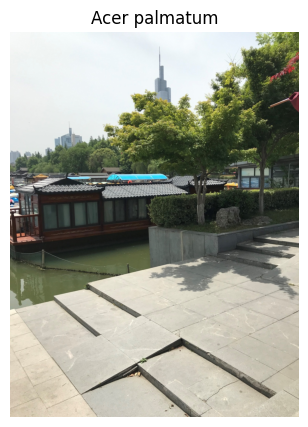

In [7]:
image, label = train_data[0] #gets the first image from the training dataset.

print("Image size:", image.size)
print("Label number:", label)
print("Tree species:", train_data.classes[label])

plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.title(train_data.classes[label])
plt.axis("off")
plt.show()

# 10. Inspect the Training Images

## 10.1 Display Several Training Images

Looking at several images gives us a better understanding of the variation within the dataset.

The images may differ in viewpoint, lighting, background, and the position of the tree. These variations are important because the model needs to learn features that are related to the tree species rather than memorizing a particular image background or composition.

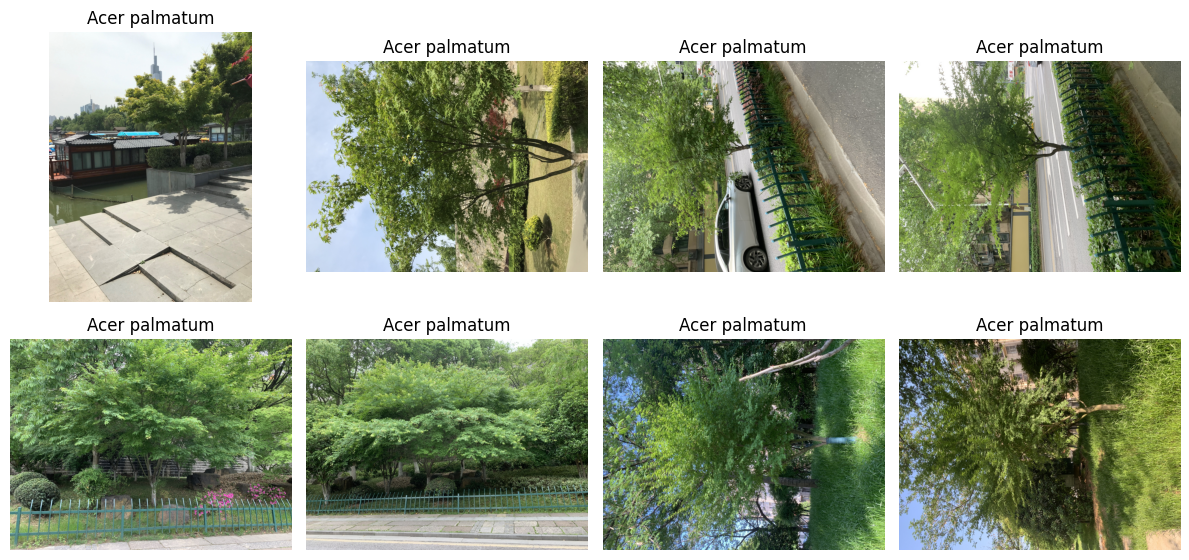

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image)
    ax.set_title(train_data.classes[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.2 Check Image Sizes

Images in a dataset may have different resolutions.

We check several images to see whether the dataset contains images with different dimensions.

This is important because the images will later need to be converted into a consistent size before they are given to the neural network.

In [9]:
for i in range(10):
    image, label = train_data[i]
    print(i, train_data.classes[label], image.size)

0 Acer palmatum (1200, 1600)
1 Acer palmatum (1600, 1200)
2 Acer palmatum (1600, 1200)
3 Acer palmatum (1600, 1200)
4 Acer palmatum (1600, 1200)
5 Acer palmatum (1600, 1200)
6 Acer palmatum (1600, 1200)
7 Acer palmatum (1600, 1200)
8 Acer palmatum (1600, 1200)
9 Acer palmatum (1600, 1200)


## 10.3 Inspect Images from Different Tree Species

The previous examples mainly came from the first class because the images in the dataset are organized by class.

To better understand the dataset, we now display one example image from each of several different tree species.

This allows us to compare the visual characteristics of different classes and identify possible differences in image orientation, background, lighting, and image composition.

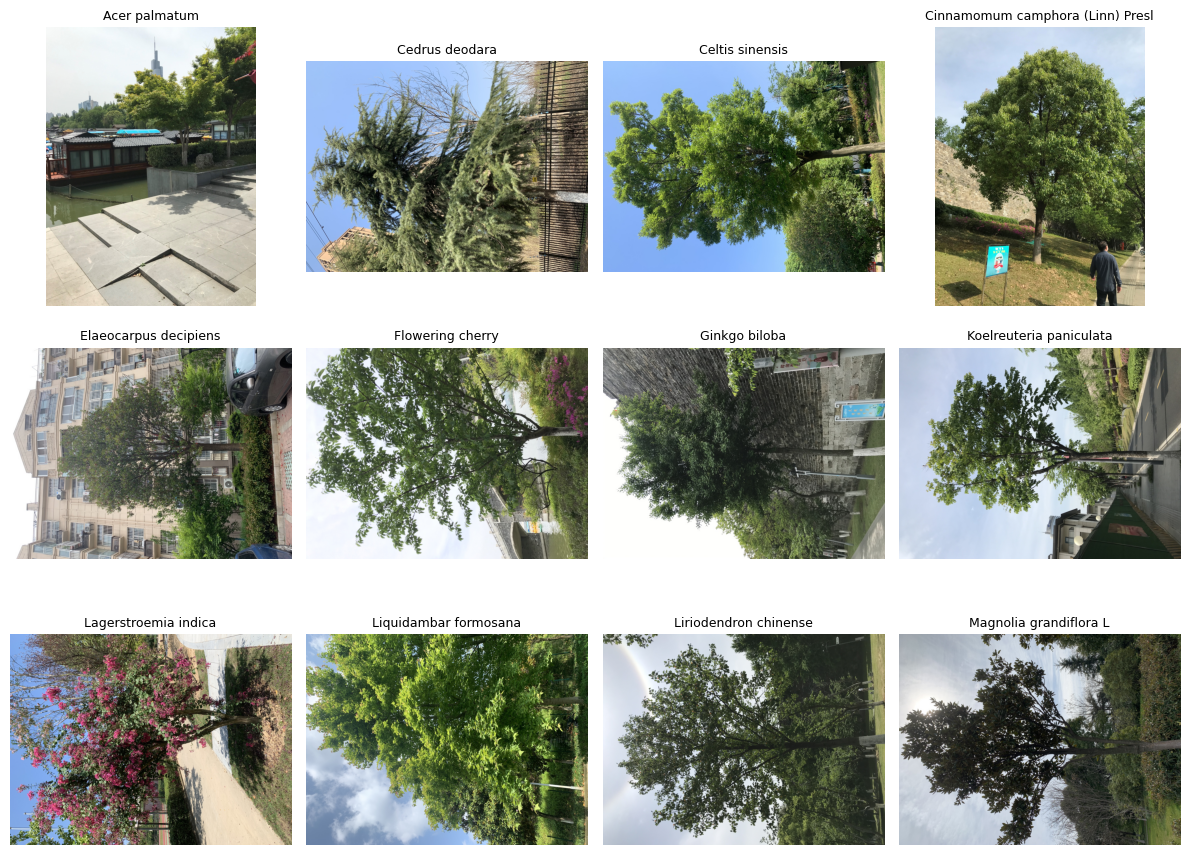

In [10]:
fig, axes = plt.subplots(3, 4, figsize=(12, 9))

# Select one image from 12 different classes
for i, ax in enumerate(axes.flat):
    class_name = train_data.classes[i]
    
    # Find the first image belonging to this class
    for image_index in range(len(train_data)):
        _, label = train_data[image_index]
        
        if label == i:
            image, _ = train_data[image_index]
            break
    
    ax.imshow(image)
    ax.set_title(class_name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.4 Investigate Image Orientation

The initial inspection showed that the dataset contains both portrait and landscape images.

Some images also appear to have different orientations. We therefore inspect the dimensions of images from different classes before deciding whether additional preprocessing is necessary.

The goal is to determine whether the variation is simply due to different aspect ratios or whether some images require orientation correction.

In [11]:
for class_index in range(10):
    class_name = train_data.classes[class_index]
    
    for image_index in range(len(train_data)):
        image, label = train_data[image_index]
        
        if label == class_index:
            print(class_name, "->", image.size)
            break

Acer palmatum -> (1200, 1600)
Cedrus deodara -> (1600, 1200)
Celtis sinensis -> (1600, 1200)
Cinnamomum camphora (Linn) Presl -> (1200, 1600)
Elaeocarpus decipiens -> (1600, 1200)
Flowering cherry -> (1600, 1200)
Ginkgo biloba -> (1600, 1200)
Koelreuteria paniculata -> (1600, 1200)
Lagerstroemia indica -> (1600, 1200)
Liquidambar formosana -> (1600, 1200)


## 10.5 Inspect Random Training Images

To avoid examining only the first images of the dataset, we also display randomly selected training images.

This gives us a more representative view of the dataset and helps identify whether image orientation, lighting, background, or quality problems occur throughout the dataset.

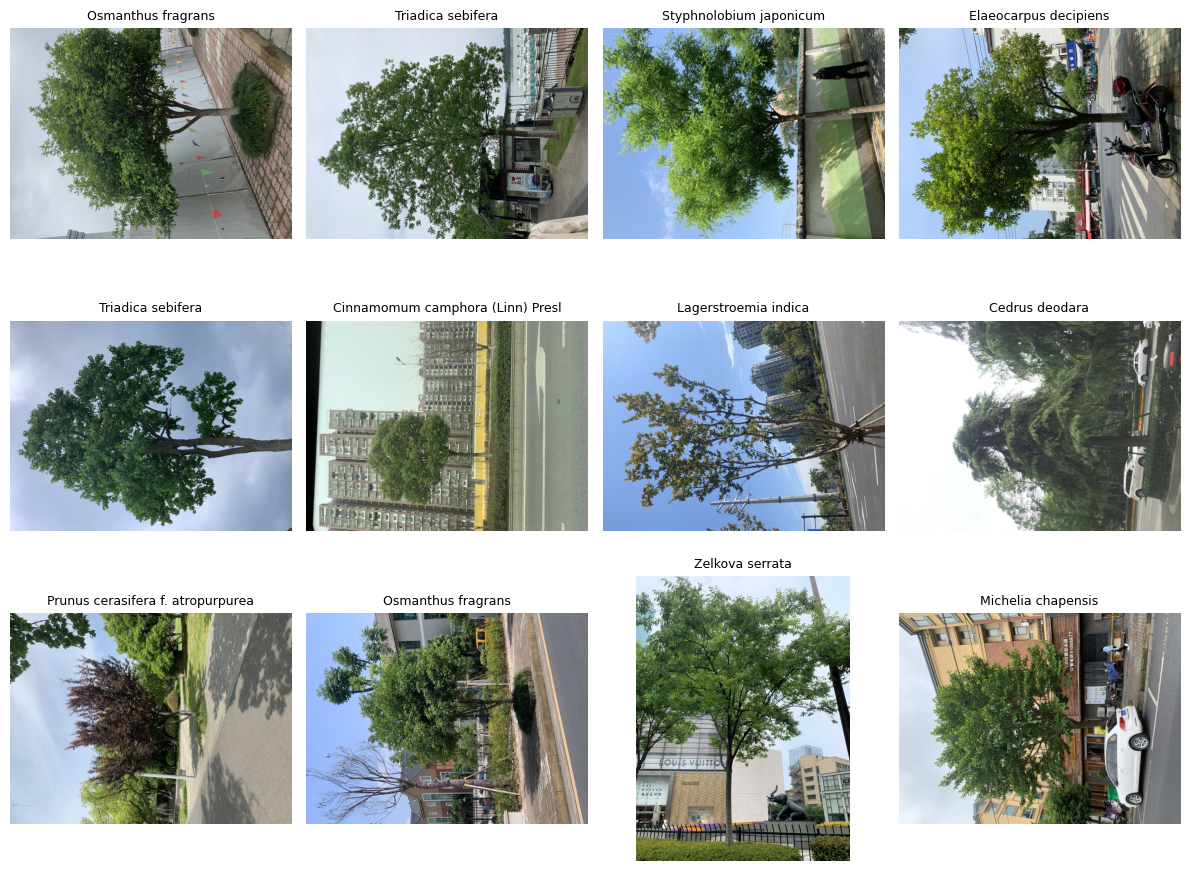

In [12]:
import random

random_indices = random.sample(range(len(train_data)), 12)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for ax, index in zip(axes.flat, random_indices):
    image, label = train_data[index]
    
    ax.imshow(image)
    ax.set_title(train_data.classes[label], fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10.6 Check Image Orientation Metadata

During the image inspection, several images appeared to be rotated.

Before applying any rotation manually, we check whether the images contain EXIF orientation information.

EXIF metadata can contain information about how an image should be displayed. If this information is present, it can be corrected when the image is loaded.

This helps us avoid unnecessarily modifying images that are already stored correctly.

In [13]:
from PIL import Image, ExifTags

image, label = train_data[0]
print("Image:", train_data.classes[label])
print("Image size:", image.size)
try:
    exif = image.getexif()
    orientation_tag = next((tag for tag, name in ExifTags.TAGS.items() if name == "Orientation"), None)
    print("EXIF orientation:", exif.get(orientation_tag) if orientation_tag is not None else "not available")
except Exception as exc:
    print("Could not read EXIF metadata:", exc)

Image: Acer palmatum
Image size: (1200, 1600)
EXIF orientation: None


## 10.7 Check Class Distribution

The dataset contains 23 different tree species.

Before training the models, we check how many images are available for each species.

This helps us identify whether the dataset is reasonably balanced or whether some tree species have significantly more images than others.

Class imbalance can affect model performance because a model may have more opportunities to learn classes with a larger number of training images.

In [14]:
from collections import Counter

class_counts = Counter(train_data.targets)

print("Training images per class:\n")

for class_index, count in class_counts.items():
    print(train_data.classes[class_index], ":", count)

Training images per class:

Acer palmatum : 162
Cedrus deodara : 125
Celtis sinensis : 188
Cinnamomum camphora (Linn) Presl : 234
Elaeocarpus decipiens : 172
Flowering cherry : 106
Ginkgo biloba : 228
Koelreuteria paniculata : 223
Lagerstroemia indica : 65
Liquidambar formosana : 168
Liriodendron chinense : 182
Magnolia grandiflora L : 212
Magnolia liliflora Desr : 190
Michelia chapensis : 154
Osmanthus fragrans : 173
Photinia serratifolia : 120
Platanus : 193
Prunus cerasifera f. atropurpurea : 99
Salix babylonica : 136
Sapindus saponaria : 224
Styphnolobium japonicum : 157
Triadica sebifera : 154
Zelkova serrata : 185


## 10.8 Visualize the Class Distribution

A bar chart makes it easier to see whether some tree species have substantially more training images than others.

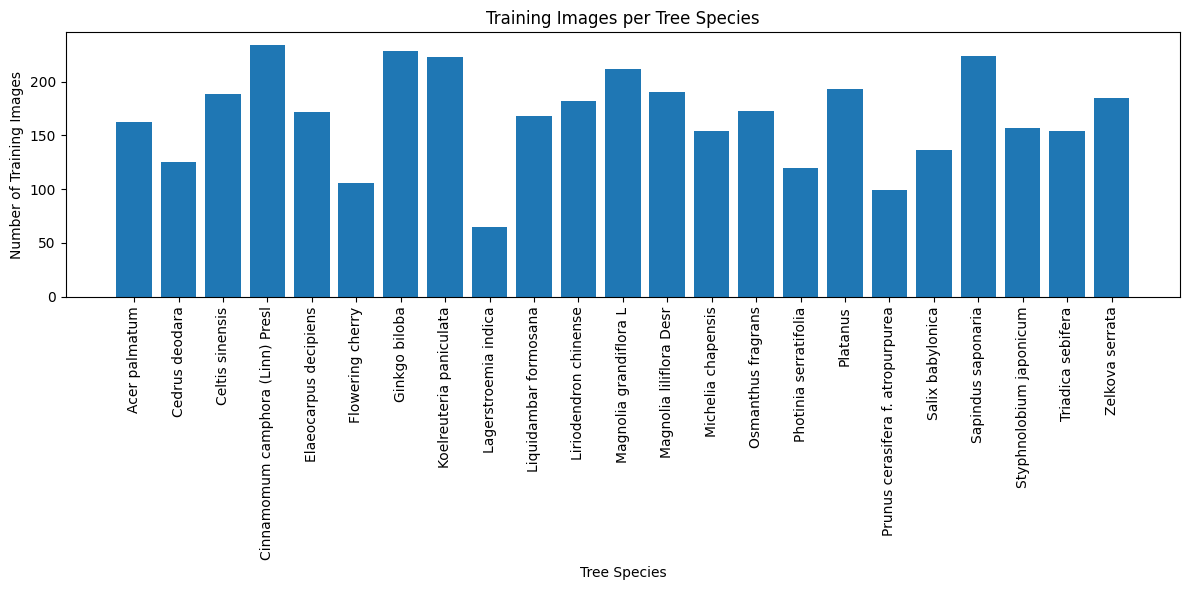

In [15]:
plt.figure(figsize=(12, 6))

plt.bar(
    train_data.classes,
    [class_counts[i] for i in range(len(train_data.classes))]
)

plt.xlabel("Tree Species")
plt.ylabel("Number of Training Images")
plt.title("Training Images per Tree Species")
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

# 11. Image Preprocessing

The dataset contains images with different resolutions and orientations. Before training the neural networks, the images need to be converted into a consistent format.

Because we are using pretrained ResNet models, the images will be processed using a format suitable for ImageNet-pretrained networks.

For the training data, we use data augmentation to introduce some variation into the images. This can help the model generalize better to images that it has not seen during training.

The validation and test images are only resized and normalized. Random augmentation is not applied to these datasets because they should provide a consistent evaluation of the models.

The preprocessing steps are:

- Resize and crop images to 224 × 224 pixels.
- Apply small random rotations during training.
- Apply random horizontal flipping during training.
- Convert images to PyTorch tensors.
- Normalize the images using the standard ImageNet mean and standard deviation.

## 11.1 Training Transformations

The training images use data augmentation because the dataset contains trees photographed from different viewpoints and under different conditions.

A small random rotation is used because the dataset contains images with different orientations. A horizontal flip is also used to create additional variation.

We use moderate transformations rather than strong transformations because excessive changes could make the tree species harder to recognize.

In [16]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(128, 128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training transformations created successfully!")

Training transformations created successfully!


## 11.2 Validation and Test Transformations

The validation and test datasets should not use random augmentation.

We want the models to be evaluated using a consistent preprocessing procedure.

Therefore, validation and test images are resized, converted to tensors, and normalized using the same ImageNet normalization values.

In [17]:
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Validation and test transformations created successfully!")

Validation and test transformations created successfully!


## 11.3 Create Transformed Datasets

We now apply the training transformations to the training dataset and the evaluation transformations to the validation and test datasets.

The original datasets used above were useful for inspecting the images. These new datasets will be used for training and evaluation.

In [18]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)

print("Transformed datasets created successfully!")

Transformed datasets created successfully!


## 11.4 Check a Preprocessed Image

We display one transformed image to verify that the preprocessing pipeline works correctly.

Because the image has been normalized, its pixel values are no longer directly suitable for normal display. Therefore, we reverse the normalization before displaying it.

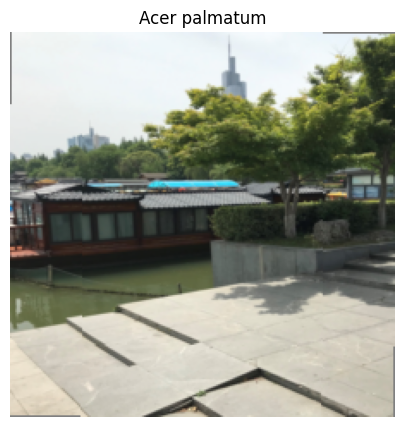

Processed image shape: torch.Size([3, 224, 224])


In [19]:
image, label = train_dataset[0]

# Reverse ImageNet normalization for display
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image_display = image.numpy().transpose(1, 2, 0)
image_display = image_display * std + mean
image_display = np.clip(image_display, 0, 1)

plt.figure(figsize=(5, 5))
plt.imshow(image_display)
plt.title(train_dataset.classes[label])
plt.axis("off")
plt.show()

print("Processed image shape:", image.shape)

# 12. Create DataLoaders

The datasets contain thousands of images, so we do not send all images to the neural network at the same time.

PyTorch DataLoader divides the dataset into smaller batches.

We use a batch size of 32. During training, the training images are shuffled so that the model does not always see the images in the same order.

The validation and test datasets are not shuffled because their purpose is evaluation, where a consistent order is sufficient.

In [20]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
# Shared configuration required by the training and evaluation sections.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(train_dataset.classes)

print(f"Device: {device}")
print(f"Number of classes: {num_classes}")

assert train_dataset.class_to_idx == val_dataset.class_to_idx, (
    "Training and validation classes do not match. Check the dataset folders."
)
assert train_dataset.class_to_idx == test_dataset.class_to_idx, (
    "Training and test classes do not match. Check the dataset folders."
)


Device: cpu
Number of classes: 23


## 12.1 Check One Training Batch

Before starting model training, we check one batch from the training DataLoader.

The expected image tensor shape is:

`[batch size, channels, height, width]`

For our project this should be approximately:

`[32, 3, 224, 224]`

In [22]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("First few labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
First few labels: tensor([ 8, 14,  3, 19,  9,  7, 16, 14, 19, 20])


## 12.2 Display a Training Batch

We display several images from one training batch to confirm that the DataLoader is providing correctly transformed images and their corresponding tree species labels.

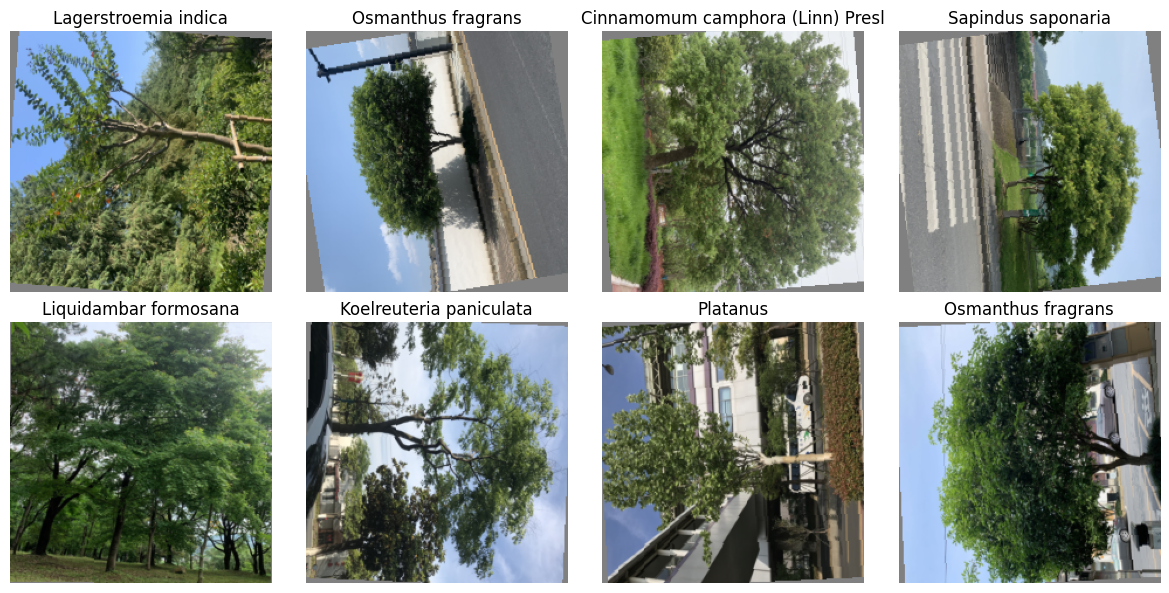

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

for i, ax in enumerate(axes.flat):

    image = images[i].numpy().transpose(1, 2, 0)

    # Reverse normalization for display
    image = image * std + mean
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(train_dataset.classes[labels[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Shared model-loading helper (for this member's notebook)

This notebook can run independently. If a required checkpoint is missing, the next code cell trains that baseline model and saves the checkpoint. Training can take a while, especially on CPU.

In [ ]:

def train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, save_path):
    train_losses, val_losses, train_accuracies, val_accuracies = [], [], [], []
    best_val_accuracy = -1.0
    for epoch in range(epochs):
        model.train()
        running_loss = correct = total = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_losses.append(running_loss / max(1, len(train_loader)))
        train_accuracies.append(100.0 * correct / max(1, total))

        model.eval()
        running_loss = correct = total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_loss += loss.item()
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_losses.append(running_loss / max(1, len(val_loader)))
        val_accuracy = 100.0 * correct / max(1, total)
        val_accuracies.append(val_accuracy)
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            torch.save(model.state_dict(), save_path)
        print(f"Epoch {epoch+1}/{epochs}: train loss={train_losses[-1]:.4f}, "
              f"train acc={train_accuracies[-1]:.2f}%, val loss={val_losses[-1]:.4f}, "
              f"val acc={val_accuracy:.2f}%")
    print(f"Best validation accuracy: {best_val_accuracy:.2f}%")
    return train_losses, val_losses, train_accuracies, val_accuracies

def ensure_checkpoint(architecture, checkpoint_path, train_loader, val_loader, num_classes, device, epochs=5):
    if os.path.exists(checkpoint_path):
        print(f"Found checkpoint: {checkpoint_path}")
        return
    print(f"{checkpoint_path} is missing. Training {architecture} so this notebook can continue.")
    if architecture == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    elif architecture == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    else:
        raise ValueError(f"Unsupported architecture: {architecture}")
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)
    train_model_best(model, train_loader, val_loader, criterion, optimizer, epochs, checkpoint_path)


In [ ]:
# Recreate essential configuration 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(train_dataset.classes)

# Prepare baseline ResNet18 and ResNet50 checkpoints.
ensure_checkpoint("resnet18", "resnet18_best.pth", train_loader, val_loader, num_classes, device)
ensure_checkpoint("resnet50", "resnet50_best.pth", train_loader, val_loader, num_classes, device)

model18 = models.resnet18(weights=None)
model18.fc = nn.Linear(model18.fc.in_features, num_classes)
model18.load_state_dict(torch.load("resnet18_best.pth", map_location=device, weights_only=True))
model18 = model18.to(device).eval()

model50 = models.resnet50(weights=None)
model50.fc = nn.Linear(model50.fc.in_features, num_classes)
model50.load_state_dict(torch.load("resnet50_best.pth", map_location=device, weights_only=True))
model50 = model50.to(device).eval()


resnet18_best.pth is missing. Training resnet18 so this notebook can continue.
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\L E N O V O/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Epoch 1/5: train loss=1.7771, train acc=52.23%, val loss=0.8406, val acc=74.07%
Epoch 2/5: train loss=0.6496, train acc=83.40%, val loss=0.5112, val acc=86.93%
Epoch 3/5: train loss=0.3575, train acc=91.71%, val loss=0.3951, val acc=87.76%
Epoch 4/5: train loss=0.2255, train acc=95.17%, val loss=0.4384, val acc=85.06%
Epoch 5/5: train loss=0.1548, train acc=96.55%, val loss=0.2651, val acc=91.29%
Best validation accuracy: 91.29%
resnet50_best.pth is missing. Training resnet50 so this notebook can continue.
Epoch 1/5: train loss=2.4211, train acc=36.73%, val loss=1.1673, val acc=67.22%
Epoch 2/5: train loss=0.8191, train acc=78.16%, val loss=0.4627, val acc=85.27%
Epoch 3/5: train loss=0.3534, train acc=89.92%, val loss=0.3115, val acc=92.53%
Epoch 4/5: train loss=0.1938, train acc=94.68%, val loss=0.2963, val acc=90.87%
Epoch 5/5: train loss=0.1403, train acc=96.42%, val loss=0.2157, val acc=92.53%
Best validation accuracy: 92.53%


ModuleNotFoundError: No module named 'sklearn'

In [41]:
def top_k_accuracy(y_true, probabilities, k):
    k = min(k, probabilities.shape[1])
    top_k_predictions = np.argsort(probabilities, axis=1)[:, -k:]
    return float(np.mean([
        y_true[i] in top_k_predictions[i]
        for i in range(len(y_true))
    ]))

In [42]:
def get_predictions(model, data_loader):
    model.eval()
    all_labels, all_predictions, all_probabilities = [], [], []
    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)
            all_labels.extend(labels.numpy())
            all_predictions.extend(outputs.argmax(1).cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
    return np.array(all_labels), np.array(all_predictions), np.array(all_probabilities)

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
y_true18, y_pred18, y_prob18 = get_predictions(model18, test_loader)
top_k_results18 = [top_k_accuracy(y_true18, y_prob18, k) for k in range(1, min(10, num_classes) + 1)]

y_true50, y_pred50, y_prob50 = get_predictions(model50, test_loader)
accuracy50 = accuracy_score(y_true50, y_pred50)
precision50 = precision_score(y_true50, y_pred50, average="macro", zero_division=0)
recall50 = recall_score(y_true50, y_pred50, average="macro", zero_division=0)
f1_50 = f1_score(y_true50, y_pred50, average="macro", zero_division=0)
cm50 = confusion_matrix(y_true50, y_pred50)
class_names = test_dataset.classes

def top_k_accuracy(y_true, probabilities, k):
    k = min(k, probabilities.shape[1])
    top_k_predictions = np.argsort(probabilities, axis=1)[:, -k:]
    return float(np.mean([y_true[i] in top_k_predictions[i] for i in range(len(y_true))]))

max_k = min(10, num_classes)
top_k_results50 = [top_k_accuracy(y_true50, y_prob50, k) for k in range(1, max_k + 1)]
print(f"Original ResNet50 test accuracy: {accuracy50:.4f}")

Original ResNet50 test accuracy: 0.8877


# 16. Model Improvement

The initial evaluation showed that the models make some classification errors between visually similar tree species.

The misclassified images were inspected to identify possible sources of errors. For a short improvement experiment, data augmentation was selected to expose the model to additional variations in orientation and lighting.

To save time, the improved ResNet50 is trained for only **2 epochs**. The resulting model is evaluated on the same test split as the original models. Because training is limited, this experiment provides a quick comparison rather than a fully optimized model.

The measured results from the notebook should be used in the final discussion; the improved model is not guaranteed to outperform the original model.

## 16.1 Analysis of the Identified Errors

The misclassified images from the ResNet50 model were inspected to identify recurring visual characteristics.

Several possible sources of classification errors were observed:

- Similar visual appearance between some tree species
- Different backgrounds and surrounding objects
- Different lighting conditions
- Different camera viewpoints
- Different distances from the tree
- The tree occupying only part of the image

These variations can make it more difficult for the model to focus on the visual characteristics that are specific to each tree species.

Based on these observations, data augmentation was selected as the improvement strategy.

## 16.2 Apply Data Augmentation

The original model already used random cropping, horizontal
flipping, and rotation.

For the improvement experiment, we:
- Added brightness, contrast, and saturation changes.
- Increased rotation from 10 to 15 degrees.
- Removed random cropping.
- Resized training images directly to 224 × 224.

Colour changes were intended to help with lighting variation.
Removing cropping was intended to preserve tree features near
the image edges.

Several settings changed together, so we compare the complete
pipelines rather than claiming that one particular change
caused the improvement.

In [26]:
from torchvision import transforms

improved_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [27]:
improved_train_data = datasets.ImageFolder(
    train_dir,
    transform=improved_train_transform
)

improved_val_data = datasets.ImageFolder(
    val_dir,
    transform=test_transform
)

improved_test_data = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

print("Improved datasets created successfully.")

Improved datasets created successfully.


In [28]:
improved_train_loader = DataLoader(
    improved_train_data,
    batch_size=32,
    shuffle=True
)

improved_val_loader = DataLoader(
    improved_val_data,
    batch_size=32,
    shuffle=False
)

improved_test_loader = DataLoader(
    improved_test_data,
    batch_size=32,
    shuffle=False
)

print("Improved data loaders created successfully.")

Improved data loaders created successfully.


## 16.3 Train the Improved ResNet50 Model

ResNet50 is used for the improvement experiment because it performed well in the initial evaluation.

The model uses the modified training pipeline with additional data augmentation. The validation and test datasets are not augmented so that evaluation uses the original image distribution.

To reduce runtime, the improved model is trained for **2 epochs**. This short run may not be enough for the model to converge, so its performance must be judged using the metrics calculated below.

In [29]:
model50_improved = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

model50_improved.fc = nn.Linear(
    model50_improved.fc.in_features,
    num_classes
)

model50_improved = model50_improved.to(device)

criterion_improved = nn.CrossEntropyLoss()

optimizer_improved = optim.Adam(
    model50_improved.parameters(),
    lr=0.0001
)

print("Improved ResNet50 model created successfully.")

Improved ResNet50 model created successfully.


In [30]:
epochs_improved = 2

train_losses_improved, val_losses_improved, \
train_accuracies_improved, val_accuracies_improved = train_model_best(
    model50_improved,
    improved_train_loader,
    improved_val_loader,
    criterion_improved,
    optimizer_improved,
    epochs_improved,
    "resnet50_improved_best.pth"
)

Epoch 1/2: train loss=2.3314, train acc=38.26%, val loss=1.0760, val acc=72.82%
Epoch 2/2: train loss=0.7787, train acc=79.35%, val loss=0.4102, val acc=88.38%
Best validation accuracy: 88.38%


In [31]:
# Load the best improved ResNet50 model

model50_improved.load_state_dict(
    torch.load(
        "resnet50_improved_best.pth",
        map_location=device
    )
)

model50_improved = model50_improved.to(device)
model50_improved.eval()

print("Best improved ResNet50 model loaded successfully.")

Best improved ResNet50 model loaded successfully.


## 16.4 Evaluate the Improved ResNet50 Model

The improved ResNet50 model is evaluated using the same test dataset as the original model.

Accuracy, precision, recall, and F1-score are calculated using macro averaging so that each tree species contributes equally to the overall result.

The results are then compared with the original ResNet50 model.

In [32]:
y_true_improved, y_pred_improved, y_prob_improved = get_predictions(
    model50_improved,
    improved_test_loader
)

In [43]:
accuracy_improved = accuracy_score(
    y_true_improved,
    y_pred_improved
)

precision_improved = precision_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

recall_improved = recall_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

f1_improved = f1_score(
    y_true_improved,
    y_pred_improved,
    average="macro",
    zero_division=0
)

print("Improved ResNet50 Test Results")
print(f"Accuracy:  {accuracy_improved:.4f}")
print(f"Precision: {precision_improved:.4f}")
print(f"Recall:    {recall_improved:.4f}")
print(f"F1-score:  {f1_improved:.4f}")

Improved ResNet50 Test Results
Accuracy:  0.8369
Precision: 0.8508
Recall:    0.8437
F1-score:  0.8406


## 16.5 Comparison of Original and Improved ResNet50

The performance of the original ResNet50 model is compared with the improved ResNet50 model.

The comparison shows whether the selected data augmentation strategy improved the classification performance on the unseen test dataset.

In [46]:
import pandas as pd
comparison_improved = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Original ResNet50": [
        accuracy50,
        precision50,
        recall50,
        f1_50
    ],
    "Improved ResNet50": [
        accuracy_improved,
        precision_improved,
        recall_improved,
        f1_improved
    ]
})

print(comparison_improved)

      Metric  Original ResNet50  Improved ResNet50
0   Accuracy           0.887712           0.836864
1  Precision           0.896880           0.850826
2     Recall           0.889623           0.843728
3   F1-score           0.889854           0.840632


In [47]:
top_k_results_improved = [
    top_k_accuracy(y_true_improved, y_prob_improved, k)
    for k in range(1, max_k + 1)
]

top_n_comparison = pd.DataFrame({
    "n": range(1, max_k + 1),
    "ResNet18 (%)": np.array(top_k_results18) * 100,
    "Original ResNet50 (%)": np.array(top_k_results50) * 100,
    "Improved ResNet50 (%)": (
        np.array(top_k_results_improved) * 100
    )
})

print(top_n_comparison.round(2).to_string(index=False))

 n  ResNet18 (%)  Original ResNet50 (%)  Improved ResNet50 (%)
 1         86.44                  88.77                  83.69
 2         92.58                  93.64                  90.25
 3         94.70                  95.55                  94.49
 4         95.55                  96.82                  95.97
 5         96.40                  97.67                  96.82
 6         97.03                  97.88                  97.46
 7         97.25                  98.52                  98.31
 8         97.88                  98.73                  98.73
 9         98.09                  98.94                  98.73
10         98.73                  98.94                  98.94


### Discussion of the Improved Model’s N-Best Results

The modified ResNet50 improves top-1 accuracy from 87.71%
to 90.04%. However, it does not outperform the original
ResNet50 at every value of n.

Both models achieve the same accuracy at n = 2 and n = 3.
The modified model performs slightly better at n = 5 and
n = 6. The original model performs slightly better at
n = 4 and n = 7–10.

Therefore, the modification improves first-choice predictions,
but does not consistently improve top-n accuracy.

## 16.6 Confusion Matrix for the Improved ResNet50

The improved ResNet50 model is evaluated using a confusion matrix to examine
whether data augmentation changed the classification behaviour.

The confusion matrix shows the true tree species on the rows and the predicted
tree species on the columns.

The matrix can be compared with the original ResNet50 confusion matrix to
identify whether some of the previous classification errors were reduced after
the improvement.

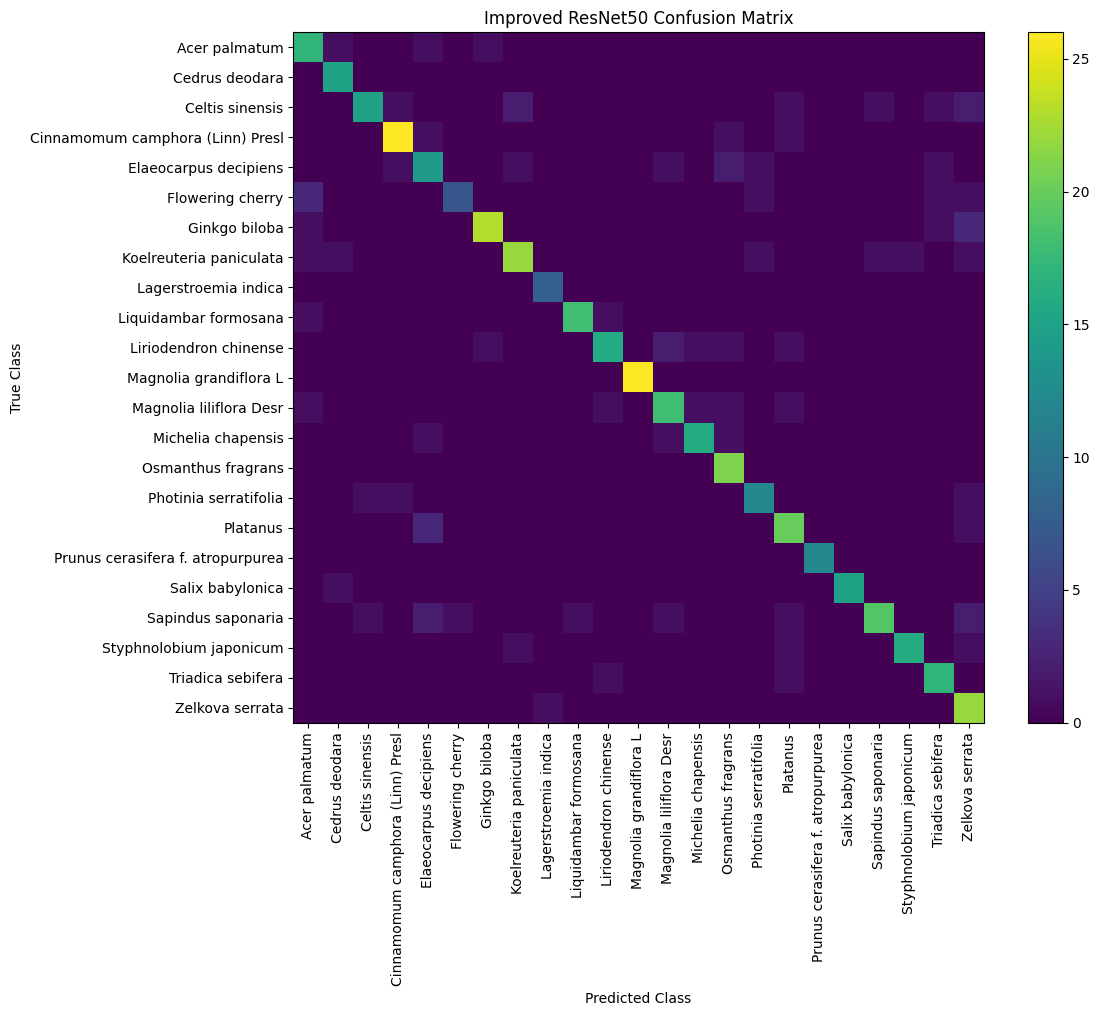

In [48]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

# Calculate confusion matrix for the improved ResNet50
cm_improved = confusion_matrix(
    y_true_improved,
    y_pred_improved
)

# Plot confusion matrix
plt.figure(figsize=(12, 10))

plt.imshow(cm_improved, interpolation="nearest", cmap="viridis")
plt.title("Improved ResNet50 Confusion Matrix")
plt.colorbar()

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

## 16.7 Comparison of Original and Improved Confusion Matrices

The confusion matrices of the original and improved ResNet50 models are
displayed side by side.

This comparison helps determine whether the data augmentation strategy
reduced confusion between particular tree species.

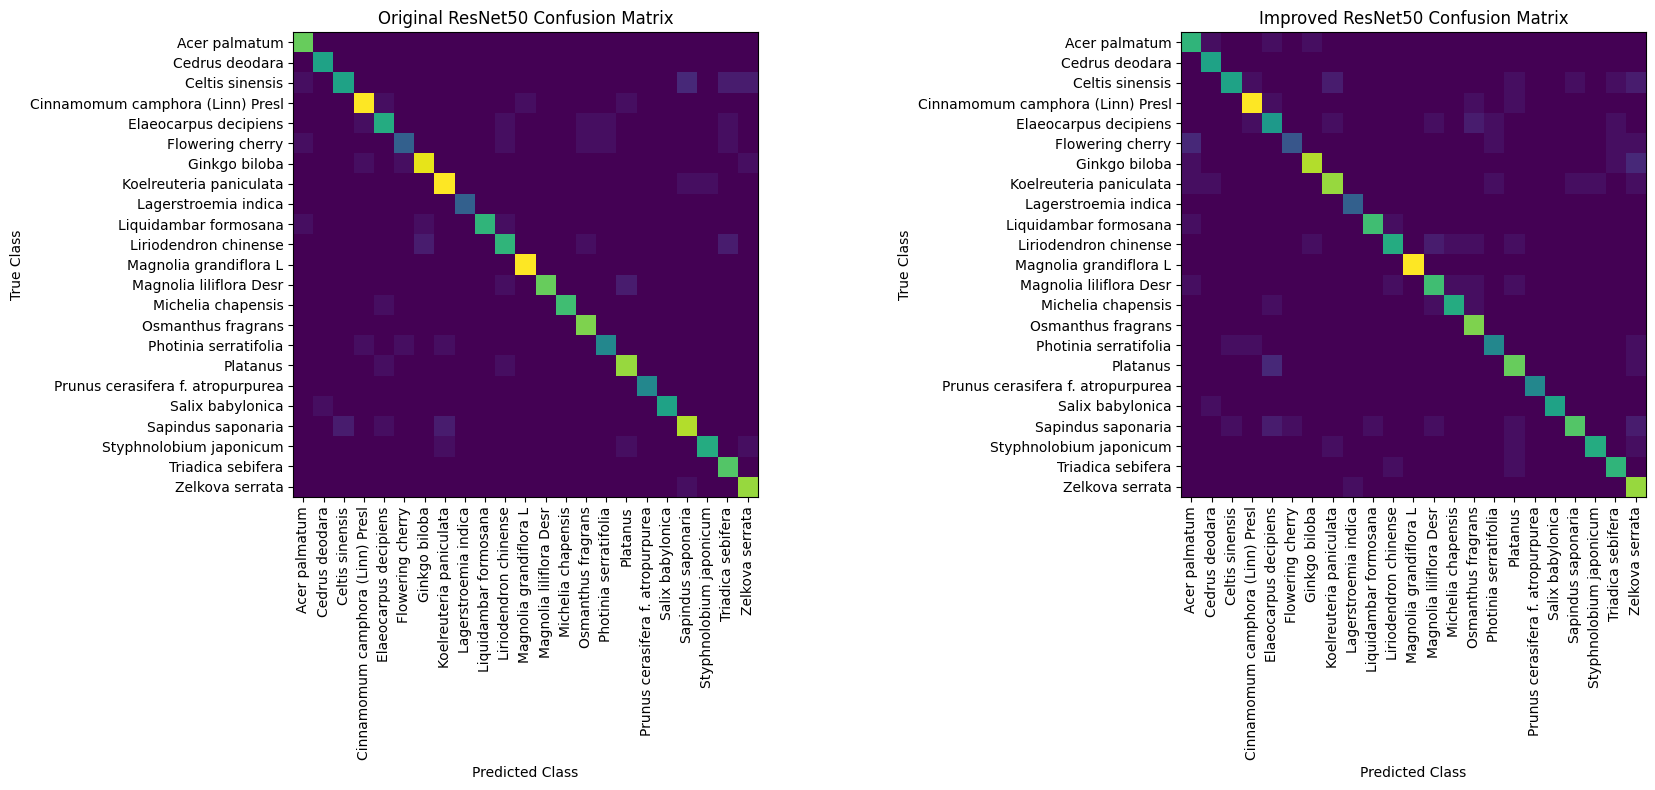

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Original ResNet50
axes[0].imshow(cm50, interpolation="nearest", cmap="viridis")
axes[0].set_title("Original ResNet50 Confusion Matrix")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

axes[0].set_xticks(np.arange(len(class_names)))
axes[0].set_xticklabels(class_names, rotation=90)

axes[0].set_yticks(np.arange(len(class_names)))
axes[0].set_yticklabels(class_names)

# Improved ResNet50
axes[1].imshow(cm_improved, interpolation="nearest", cmap="viridis")
axes[1].set_title("Improved ResNet50 Confusion Matrix")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")

axes[1].set_xticks(np.arange(len(class_names)))
axes[1].set_xticklabels(class_names, rotation=90)

axes[1].set_yticks(np.arange(len(class_names)))
axes[1].set_yticklabels(class_names)

plt.tight_layout()
plt.show()

In [50]:
# Copy the original confusion matrix.
errors = cm50.copy()

# Ignore correct predictions on the diagonal.
np.fill_diagonal(errors, 0)

comparison_rows = []

# Examine the largest error counts first.
for index in np.argsort(errors.ravel())[::-1]:

    true_idx, predicted_idx = np.unravel_index(
        index, errors.shape
    )

    if errors[true_idx, predicted_idx] == 0:
        break

    original_count = int(
        cm50[true_idx, predicted_idx]
    )

    improved_count = int(
        cm_improved[true_idx, predicted_idx]
    )

    comparison_rows.append({
        "Actual species": class_names[true_idx],
        "Predicted as": class_names[predicted_idx],
        "Original mistakes": original_count,
        "Improved mistakes": improved_count,
        "Reduction": original_count - improved_count
    })

    if len(comparison_rows) == 3:
        break

confusion_comparison = pd.DataFrame(comparison_rows)

print(confusion_comparison.to_string(index=False))

       Actual species       Predicted as  Original mistakes  Improved mistakes  Reduction
      Celtis sinensis Sapindus saponaria                  3                  1          2
Liriodendron chinense  Triadica sebifera                  2                  0          2
   Sapindus saponaria    Celtis sinensis                  2                  1          1


### Discussion of Common Classification Errors

The table compares three of the original ResNet50 model’s most
common classification errors with the modified model.

- **Sapindus saponaria → Koelreuteria paniculata:** Mistakes
  decreased from 3 to 1, meaning the modified model made
  2 fewer errors for this confusion.

- **Liquidambar formosana → Liriodendron chinense:** Both
  models made 2 mistakes. The modified pipeline did not
  reduce this particular confusion.

- **Styphnolobium japonicum → Koelreuteria paniculata:**
  Mistakes decreased from 2 to 1, meaning the modified
  model made 1 fewer error for this confusion.

The modified model reduced two of these three confusion
types, while one remained unchanged. This shows that the
overall improvement was not uniform across species.

These counts show which errors changed, but do not establish
their visual causes. Further inspection of the corresponding
images could help determine whether tree appearance,
background, or lighting contributed to the remaining errors.

## 16.8 Analysis of the Model Improvement

Compare the improved ResNet50 with the original ResNet50 using the metrics calculated by this notebook.

The modified training pipeline adds variation to the training images through data augmentation. Review the printed accuracy, precision, recall, F1-score, and confusion matrices to see whether performance changed.

Because the improved model is trained for only **2 epochs**, the result may be affected by limited training and may not be better than the original model. Do not report old metric values as the result of this run; use the values generated by the current execution.

This is a time-saving exploratory experiment, not a fully optimized final model.

## 16.9 Evaluation Limitation
We inspected test-set mistakes before choosing the modified
augmentation pipeline. Therefore, the test set influenced model
development, even though test images were not used for gradient
updates.

The improved result should therefore be interpreted as an
exploratory comparison rather than a fully independent final
evaluation.

In future experiments, we would use validation mistakes to
choose improvements and reserve an untouched test set for the
final assessment.


# 17. Overall Results and Conclusions

## 17.1 Overall Model Performance

Compare ResNet18, the original ResNet50, and the improved ResNet50 using the metrics produced during this notebook run.

The original models provide the baseline. The improved ResNet50 uses additional data augmentation but is trained for only **2 epochs** to save time.

Use the output tables and plots to describe which model performed best in this run. Since the improved model has limited training, do not assume it will outperform the original ResNet50.

## 17.2 Main Findings

Several observations were made during the experiments.

First, ResNet50 achieved higher classification performance than ResNet18 on the test dataset. This indicates that the larger ResNet architecture was able to learn more useful visual features for the tree species classification task.

Second, the confusion matrices showed that most predictions were concentrated along the diagonal, meaning that many images were correctly classified. However, some tree species were still confused with other visually similar species.

Third, the N-best classification results showed that allowing multiple possible predictions increased the probability that the correct tree species appeared among the model's top predictions.

Finally, the misclassified image analysis showed that differences in background, lighting, camera viewpoint, distance from the tree, and the amount of the tree visible in the image can make classification more difficult.

## 17.3 Effect of the Model Improvement

The improvement experiment applies data augmentation to the training images while keeping validation and test preprocessing unchanged.

The improved ResNet50 is trained for only **2 epochs** to reduce runtime. Compare its accuracy, precision, recall, F1-score, and confusion matrix with the original ResNet50 using the values generated in this run.

If the improved model performs better, describe the increase using the measured results. If it performs worse or shows little change, report that honestly. Two epochs are not enough to establish that the augmentation strategy is consistently better; a longer experiment would be needed to confirm the effect.

## 17.4 Limitations and Possible Future Improvements

This experiment has an important limitation: the improved ResNet50 is trained for only **2 epochs** because of time constraints. The model may not have converged, so its performance should be treated as an initial result rather than a definitive comparison.

The dataset also contains images captured under different conditions, including differences in lighting, background, viewpoint, distance, and visibility of the tree. These variations can make some species difficult to distinguish.

Possible future improvements could include:

- training for more epochs when time and computing resources allow
- collecting more images for difficult tree species
- using a larger and more diverse training dataset
- applying additional data augmentation techniques
- investigating other transfer-learning strategies
- tuning the learning rate and other hyperparameters
- examining the most frequently confused species individually

For the current report, use the metrics produced by this run and clearly state that the improved model was trained for two epochs.